# IT462: Exploratory Data Analysis
## Lab Assignment 11: Classification - Predicting Diabetes

This notebook follows the assignment instructions: `random_state=42`, one stratified 75/25 train/test split shared by all models, missing-value medians learned from the training set only, and a short interpretation for each question.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay, confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries loaded. Random state =", RANDOM_STATE)

Libraries loaded. Random state = 42


## Part A — Understanding the Data

### Q1. Load and inspect the dataset

Shape: (768, 9)

Data types:
Pregnancies           int64
Glucose               int64
BloodPressure         int64
SkinThickness         int64
Insulin               int64
BMI                 float64
DiabetesPedigree    float64
Age                   int64
Outcome               int64
dtype: object

First five rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Descriptive statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


,Count,Percentage
No diabetes (0),500,65.1
Diabetes (1),268,34.9


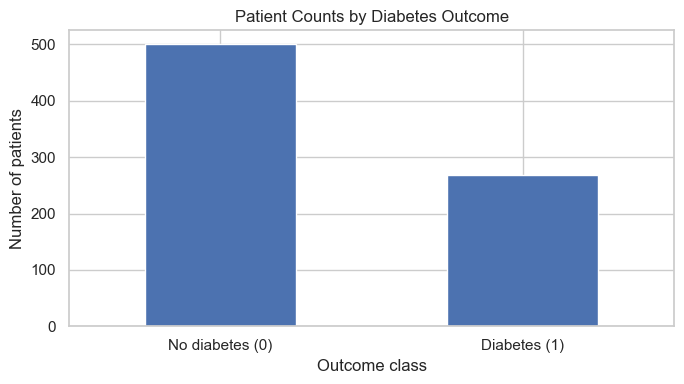

Interpretation: The dataset contains 768 patients and 8 input measurements. The classes are not the same size; 34.9% of patients have diabetes and 65.1% do not.


In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
        "BMI", "DiabetesPedigree", "Age", "Outcome"]

try:
    df = pd.read_csv(url, header=None, names=cols)
except Exception as exc:
    raise RuntimeError(
        "Could not download the dataset. Download the CSV from the assignment's GitHub link "
        "and replace the URL above with the local CSV file path."
    ) from exc

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nFirst five rows:")
display(df.head())
print("\nDescriptive statistics:")
display(df.describe())

class_counts = df["Outcome"].value_counts().sort_index()
class_pct = (df["Outcome"].value_counts(normalize=True).sort_index() * 100)
class_summary = pd.DataFrame({"Count": class_counts, "Percentage": class_pct.round(2)})
class_summary.index = ["No diabetes (0)", "Diabetes (1)"]
display(class_summary)

ax = class_summary["Count"].plot(kind="bar", figsize=(7, 4), title="Patient Counts by Diabetes Outcome")
ax.set_xlabel("Outcome class")
ax.set_ylabel("Number of patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Interpretation: The dataset contains {df.shape[0]} patients and {df.shape[1]-1} input measurements. "
      f"The classes are {'the same size' if class_counts.nunique()==1 else 'not the same size'}; "
      f"{class_pct.loc[1]:.1f}% of patients have diabetes and {class_pct.loc[0]:.1f}% do not.")

### Q2. Identify hidden missing values
A zero can be a valid value for `Pregnancies` because a patient may never have been pregnant. In contrast, zero glucose, blood pressure, skin thickness, insulin, or BMI values are treated as missing in this assignment.

In [3]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_cols] == 0).sum()
print("Zero values in the specified columns:")
display(zero_counts.to_frame("Zero count"))

df[zero_cols] = df[zero_cols].replace(0, np.nan)
missing_pct = (df.isna().mean() * 100).round(1)
print("Percentage missing by column:")
display(missing_pct.to_frame("Missing (%)"))

print("Interpretation: The zero values in the five specified medical measurements are treated as missing rather than real measurements. "
      "Pregnancies is different because zero pregnancies is a plausible observation.")

Zero values in the specified columns:


,Zero count
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


Percentage missing by column:


,Missing (%)
Pregnancies,0.0
Glucose,0.7
BloodPressure,4.6
SkinThickness,29.6
Insulin,48.7
BMI,1.4
DiabetesPedigree,0.0
Age,0.0
Outcome,0.0


Interpretation: The zero values in the five specified medical measurements are treated as missing rather than real measurements. Pregnancies is different because zero pregnancies is a plausible observation.


### Q3. Compare the two outcome groups

Column medians by Outcome (0 = no diabetes, 1 = diabetes):


Outcome,0,1
Pregnancies,2.000,4.000
Glucose,107.000,140.000
BloodPressure,70.000,74.500
SkinThickness,27.000,32.000
Insulin,102.500,169.500
BMI,30.100,34.300
DiabetesPedigree,0.336,0.449
Age,27.000,36.000


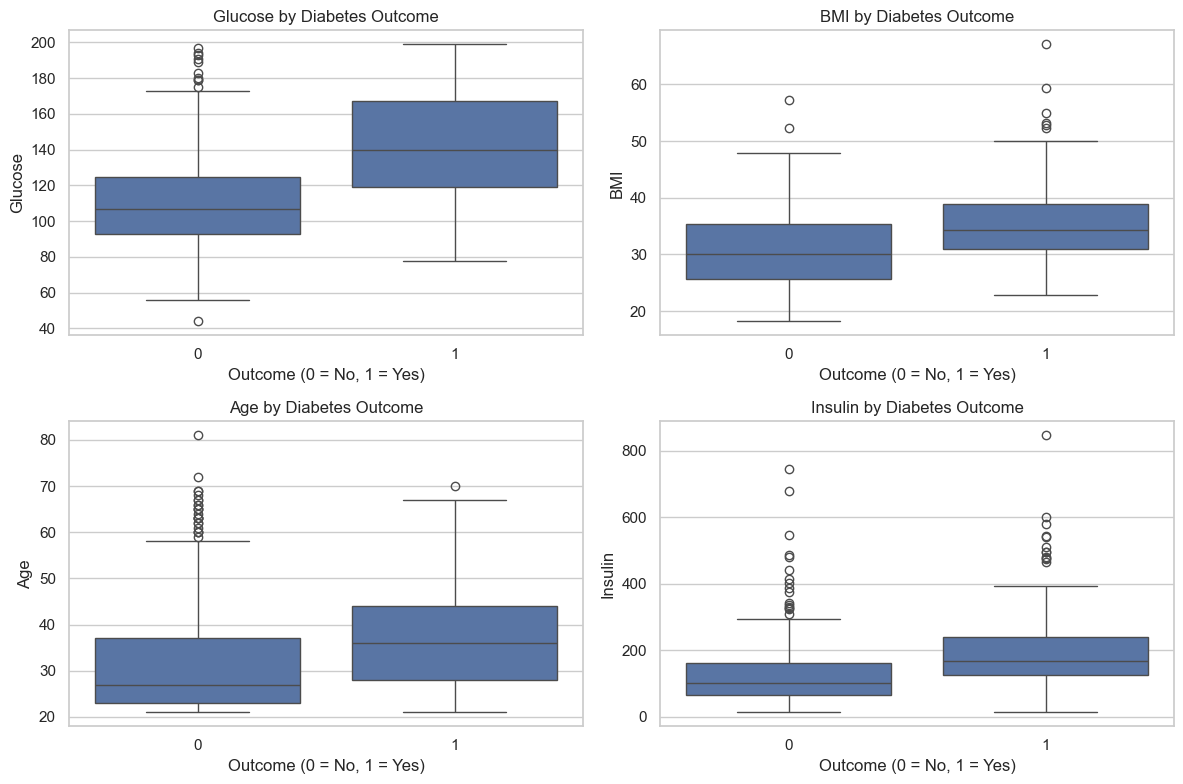

Absolute difference between group medians:


,Absolute median difference
Insulin,67.0
Glucose,33.0
Age,9.0
BMI,4.2


Interpretation: The largest median gaps among the four plotted measurements are Insulin, Glucose, Age. The boxplots also show the spread and overlap of the two groups, not just their medians.


In [4]:
print("Column medians by Outcome (0 = no diabetes, 1 = diabetes):")
display(df.groupby("Outcome").median(numeric_only=True).T)

plot_cols = ["Glucose", "BMI", "Age", "Insulin"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(plot_cols, axes.flat):
    sns.boxplot(data=df, x="Outcome", y=col, ax=ax)
    ax.set_title(f"{col} by Diabetes Outcome")
    ax.set_xlabel("Outcome (0 = No, 1 = Yes)")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

medians = df.groupby("Outcome")[plot_cols].median()
median_gaps = (medians.loc[1] - medians.loc[0]).abs().sort_values(ascending=False)
print("Absolute difference between group medians:")
display(median_gaps.to_frame("Absolute median difference"))
print("Interpretation: The largest median gaps among the four plotted measurements are "
      + ", ".join(median_gaps.index[:3]) +
      ". The boxplots also show the spread and overlap of the two groups, not just their medians.")

### Q4. Correlation heatmap

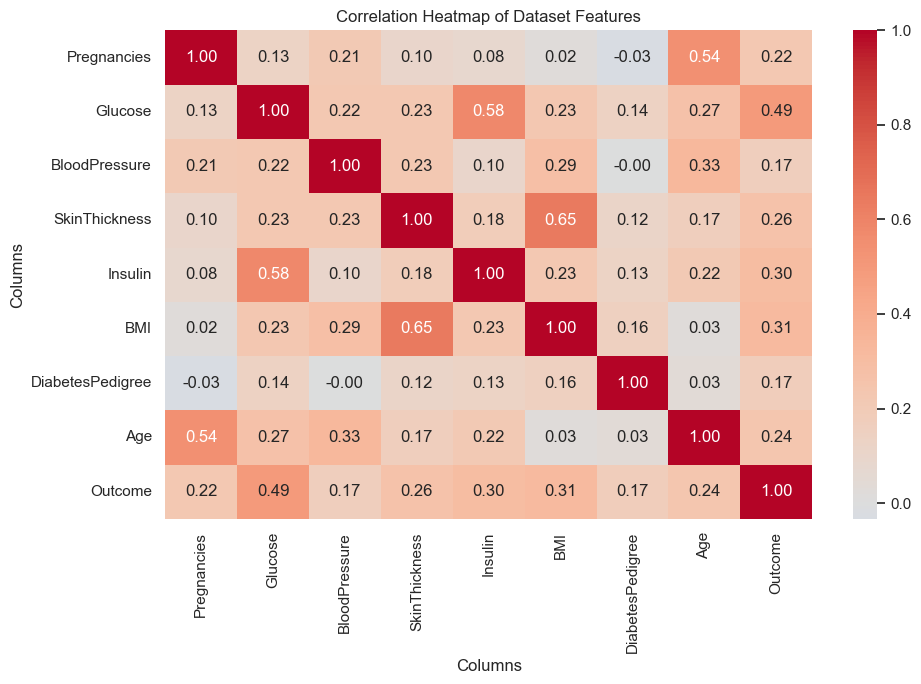

Features most correlated with Outcome (ranked by absolute correlation):


,Correlation with Outcome
Glucose,0.494650
BMI,0.313680
Insulin,0.303454


Interpretation: The three strongest correlations by absolute value are Glucose, BMI, Insulin. This can be compared with Q3: correlation measures linear association, while the boxplots compare group distributions.


In [5]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Dataset Features")
plt.xlabel("Columns")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

outcome_corr = corr["Outcome"].drop("Outcome").sort_values(key=lambda s: s.abs(), ascending=False)
print("Features most correlated with Outcome (ranked by absolute correlation):")
display(outcome_corr.head(3).to_frame("Correlation with Outcome"))
print("Interpretation: The three strongest correlations by absolute value are "
      + ", ".join(outcome_corr.head(3).index) +
      ". This can be compared with Q3: correlation measures linear association, while the boxplots compare group distributions.")

## Part B — Preparing the Data for the Models

### Q5. Train/test split and imputation

In [6]:
X = df.drop(columns="Outcome")
y = df["Outcome"].astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

# Calculate medians on training data only, then use those same values for both sets.
medians_train = X_train_raw.median()
X_train = X_train_raw.fillna(medians_train)
X_test = X_test_raw.fillna(medians_train)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print(f"Diabetes percentage in training set: {y_train.mean()*100:.2f}%")
print(f"Diabetes percentage in test set: {y_test.mean()*100:.2f}%")
print("Remaining missing values — train:", int(X_train.isna().sum().sum()),
      "| test:", int(X_test.isna().sum().sum()))
print("Interpretation: The split preserves a similar diabetes proportion in both sets through stratification. "
      "Training medians are used for both sets to avoid using information from the held-out test data during preprocessing.")

X_train shape: (576, 8)
X_test shape: (192, 8)
Diabetes percentage in training set: 34.90%
Diabetes percentage in test set: 34.90%
Remaining missing values — train: 0 | test: 0
Interpretation: The split preserves a similar diabetes proportion in both sets through stratification. Training medians are used for both sets to avoid using information from the held-out test data during preprocessing.


### Q6. Baseline model: always predict no diabetes

In [7]:
def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }

baseline_pred = np.zeros(len(y_test), dtype=int)
baseline_scores = scores(y_test, baseline_pred)
display(pd.DataFrame([baseline_scores], index=["Always predict no diabetes"]).round(3))
print("Interpretation: Accuracy can look reasonably high because the no-diabetes class is larger. "
      "However, this baseline has zero recall and zero F1 for diabetes because it misses every patient who has diabetes.")

,Accuracy,Precision,Recall,F1
Always predict no diabetes,0.651,0.0,0.0,0.0


Interpretation: Accuracy can look reasonably high because the no-diabetes class is larger. However, this baseline has zero recall and zero F1 for diabetes because it misses every patient who has diabetes.


## Part C — Models

### Q7. Logistic Regression

Training scores:


,Accuracy,Precision,Recall,F1
Logistic Regression,0.785,0.742,0.587,0.656


Test scores:


,Accuracy,Precision,Recall,F1
Logistic Regression,0.729,0.636,0.522,0.574


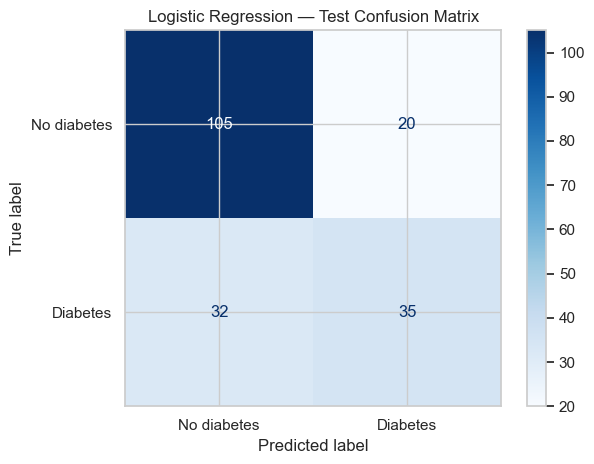

TN=105: correctly predicted no diabetes.
FP=20: predicted diabetes, but the patient is in the no-diabetes class.
FN=32: predicted no diabetes, but the patient has diabetes.
TP=35: correctly predicted diabetes.
Logistic Regression coefficients:


,Coefficient
SkinThickness,-0.0075
BloodPressure,-0.0054
Insulin,-0.0005
Age,0.0106
Glucose,0.0394
BMI,0.1106
Pregnancies,0.1354
DiabetesPedigree,0.5789


Positive coefficients: Age, Glucose, BMI, Pregnancies, DiabetesPedigree
Interpretation: Holding the other inputs fixed, positive coefficients correspond to higher modelled log-odds of diabetes. Coefficient signs describe the fitted model and do not establish causation.


In [8]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train, y_train)
logreg_train_scores = scores(y_train, logreg.predict(X_train))
logreg_test_pred = logreg.predict(X_test)
logreg_test_scores = scores(y_test, logreg_test_pred)

print("Training scores:")
display(pd.DataFrame([logreg_train_scores], index=["Logistic Regression"]).round(3))
print("Test scores:")
display(pd.DataFrame([logreg_test_scores], index=["Logistic Regression"]).round(3))

ConfusionMatrixDisplay.from_estimator(
    logreg, X_test, y_test, display_labels=["No diabetes", "Diabetes"], cmap="Blues"
)
plt.title("Logistic Regression — Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, logreg_test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}: correctly predicted no diabetes.")
print(f"FP={fp}: predicted diabetes, but the patient is in the no-diabetes class.")
print(f"FN={fn}: predicted no diabetes, but the patient has diabetes.")
print(f"TP={tp}: correctly predicted diabetes.")

coef = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
print("Logistic Regression coefficients:")
display(coef.to_frame("Coefficient").round(4))
positive_features = coef[coef > 0].index.tolist()
print("Positive coefficients:", ", ".join(positive_features) if positive_features else "None")
print("Interpretation: Holding the other inputs fixed, positive coefficients correspond to higher modelled log-odds of diabetes. "
      "Coefficient signs describe the fitted model and do not establish causation.")

### Q8. Decision Tree — default tree and depth-3 tree

,Accuracy,Precision,Recall,F1
Default tree — train,1.000,1.000,1.000,1.000
Default tree — test,0.688,0.569,0.433,0.492
Depth 3 tree — train,0.792,0.761,0.587,0.663
Depth 3 tree — test,0.708,0.608,0.463,0.525


Default tree training accuracy: 1.000. A training accuracy of 1.0 means the unrestricted tree has memorized the training examples; it may not generalize well to unseen patients.

Depth-3 tree:


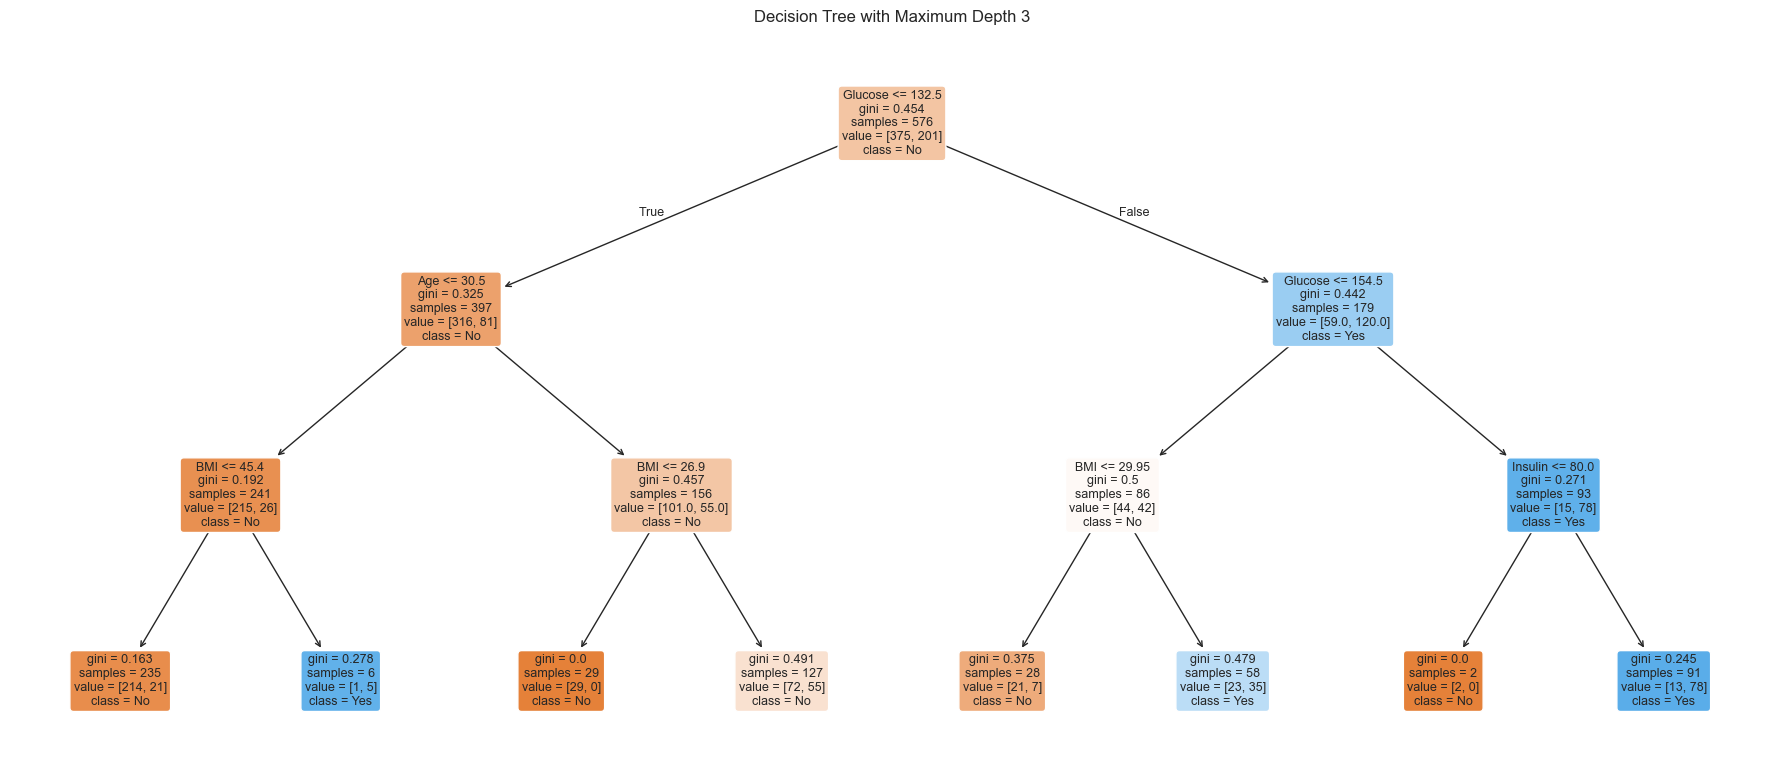

Example first root-to-leaf rule: If Glucose <= 132.50 and Age <= 30.50 and BMI <= 45.40, the depth-3 tree predicts no diabetes.
Interpretation: Restricting the depth makes the tree simpler and easier to explain. Compare the depth-3 test scores with the default tree to see whether the simpler model generalizes better.


In [9]:
tree_default = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_default.fit(X_train, y_train)
default_train_scores = scores(y_train, tree_default.predict(X_train))
default_test_scores = scores(y_test, tree_default.predict(X_test))

tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)
tree_train_scores = scores(y_train, tree.predict(X_train))
tree_test_pred = tree.predict(X_test)
tree_test_scores = scores(y_test, tree_test_pred)

display(pd.DataFrame(
    [default_train_scores, default_test_scores, tree_train_scores, tree_test_scores],
    index=["Default tree — train", "Default tree — test", "Depth 3 tree — train", "Depth 3 tree — test"]
).round(3))

print(f"Default tree training accuracy: {default_train_scores['Accuracy']:.3f}. "
      "A training accuracy of 1.0 means the unrestricted tree has memorized the training examples; "
      "it may not generalize well to unseen patients.")
print("\nDepth-3 tree:")
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=X.columns, class_names=["No", "Yes"], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree with Maximum Depth 3")
plt.tight_layout()
plt.show()

# Create one plain-language rule from the first root-to-leaf path.
from sklearn.tree import _tree
def first_leaf_rule(fitted_tree, feature_names):
    t = fitted_tree.tree_
    node = 0
    conditions = []
    while t.feature[node] != _tree.TREE_UNDEFINED:
        feat = feature_names[t.feature[node]]
        threshold = t.threshold[node]
        left = t.children_left[node]
        right = t.children_right[node]
        if left != _tree.TREE_LEAF:
            conditions.append(f"{feat} <= {threshold:.2f}")
            node = left
        else:
            conditions.append(f"{feat} > {threshold:.2f}")
            node = right
    prediction = int(np.argmax(t.value[node][0]))
    return " and ".join(conditions), prediction

rule, rule_prediction = first_leaf_rule(tree, list(X.columns))
print(f"Example first root-to-leaf rule: If {rule}, the depth-3 tree predicts "
      f"{'diabetes' if rule_prediction == 1 else 'no diabetes'}.")
print("Interpretation: Restricting the depth makes the tree simpler and easier to explain. "
      "Compare the depth-3 test scores with the default tree to see whether the simpler model generalizes better.")

### Q9. Random Forest

Training scores:


,Accuracy,Precision,Recall,F1
Random Forest,1.0,1.0,1.0,1.0


Test scores:


,Accuracy,Precision,Recall,F1
Random Forest,0.745,0.661,0.552,0.602


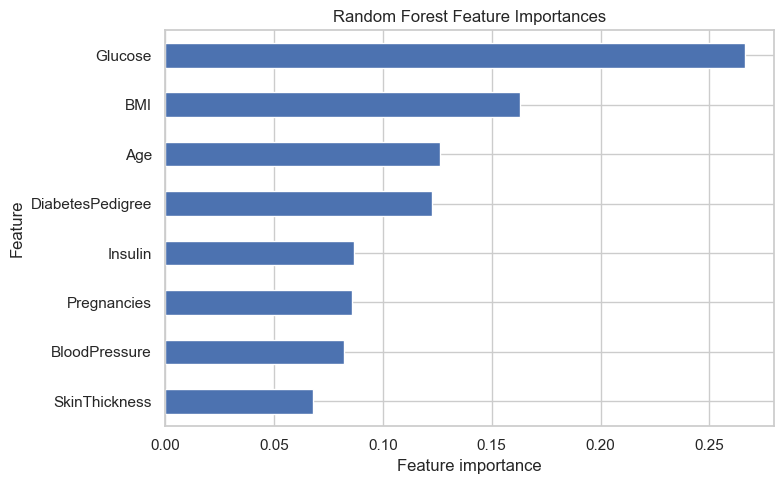

,Importance
Glucose,0.2664
BMI,0.1629
Age,0.1261
DiabetesPedigree,0.1224
Insulin,0.0868
Pregnancies,0.0857
BloodPressure,0.0820
SkinThickness,0.0677


Interpretation: The highest-importance features are Glucose, BMI, Age. Compare these with Q3's median differences and Q4's correlations; the measures can differ because they capture different relationships.


In [10]:
forest = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
forest.fit(X_train, y_train)
forest_train_scores = scores(y_train, forest.predict(X_train))
forest_test_pred = forest.predict(X_test)
forest_test_scores = scores(y_test, forest_test_pred)

print("Training scores:")
display(pd.DataFrame([forest_train_scores], index=["Random Forest"]).round(3))
print("Test scores:")
display(pd.DataFrame([forest_test_scores], index=["Random Forest"]).round(3))

importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)
ax = importances.sort_values().plot(kind="barh", figsize=(8, 5), title="Random Forest Feature Importances")
ax.set_xlabel("Feature importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()
display(importances.to_frame("Importance").round(4))
print("Interpretation: The highest-importance features are "
      + ", ".join(importances.head(3).index) +
      ". Compare these with Q3's median differences and Q4's correlations; the measures can differ because they capture different relationships.")

### Q10. Compare the models

Test-set results:


,Accuracy,Precision,Recall,F1
Baseline,0.651,0.000,0.000,0.000
Logistic Regression,0.729,0.636,0.522,0.574
Decision Tree (depth 3),0.708,0.608,0.463,0.525
Random Forest,0.745,0.661,0.552,0.602


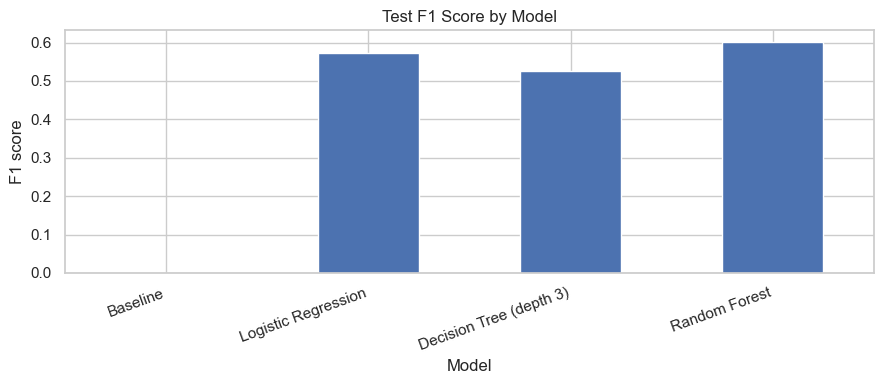

Best model by test F1: Random Forest (F1=0.602).
Models with F1 above baseline: Logistic Regression, Decision Tree (depth 3), Random Forest
Interpretation: F1 balances precision and recall, so it is more informative than accuracy alone for this imbalanced classification task. Use the displayed table to compare all models on the same held-out test set.


In [11]:
models_test = {
    "Baseline": baseline_scores,
    "Logistic Regression": logreg_test_scores,
    "Decision Tree (depth 3)": tree_test_scores,
    "Random Forest": forest_test_scores
}
results = pd.DataFrame(models_test).T[["Accuracy", "Precision", "Recall", "F1"]]
print("Test-set results:")
display(results.round(3))

ax = results["F1"].plot(kind="bar", figsize=(9, 4), title="Test F1 Score by Model")
ax.set_xlabel("Model")
ax.set_ylabel("F1 score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_model_name = results["F1"].idxmax()
beating_baseline = results.index[results["F1"] > results.loc["Baseline", "F1"]].tolist()
print(f"Best model by test F1: {best_model_name} (F1={results.loc[best_model_name, 'F1']:.3f}).")
print("Models with F1 above baseline:", ", ".join(beating_baseline))
print("Interpretation: F1 balances precision and recall, so it is more informative than accuracy alone for this imbalanced classification task. "
      "Use the displayed table to compare all models on the same held-out test set.")

## Part D — Improving and Checking the Models

### Q11. Decision-tree depth

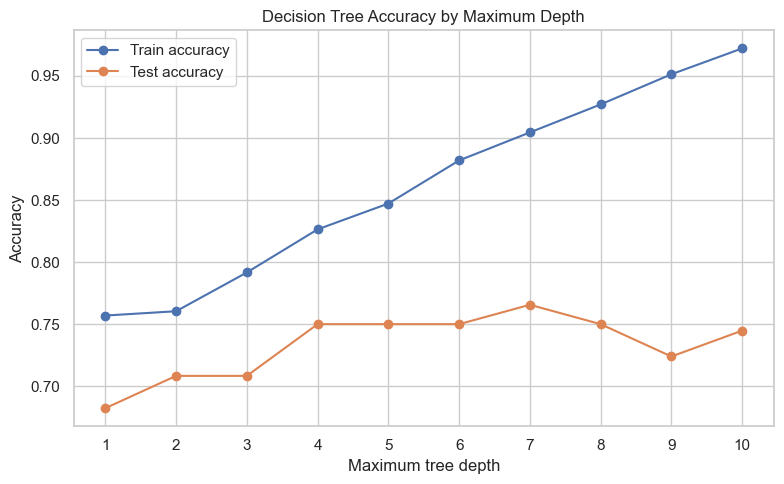

,Depth,Train accuracy,Test accuracy
0,1,0.757,0.682
1,2,0.760,0.708
2,3,0.792,0.708
3,4,0.826,0.750
4,5,0.847,0.750
5,6,0.882,0.750
6,7,0.905,0.766
7,8,0.927,0.750
8,9,0.951,0.724
9,10,0.972,0.745


Highest test accuracy occurs at depth 7 (0.766).
Interpretation: Overfitting is suggested when training accuracy continues to rise while test accuracy stops improving or falls. Use the plotted curves and table to identify the first depth where this pattern appears.


In [12]:
depths = list(range(1, 11))
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.title("Decision Tree Accuracy by Maximum Depth")
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.legend()
plt.tight_layout()
plt.show()

depth_results = pd.DataFrame({"Depth": depths, "Train accuracy": train_acc, "Test accuracy": test_acc})
display(depth_results.round(3))
best_depth_row = depth_results.loc[depth_results["Test accuracy"].idxmax()]
print(f"Highest test accuracy occurs at depth {int(best_depth_row['Depth'])} "
      f"({best_depth_row['Test accuracy']:.3f}).")
print("Interpretation: Overfitting is suggested when training accuracy continues to rise while test accuracy stops improving or falls. "
      "Use the plotted curves and table to identify the first depth where this pattern appears.")

### Q12. Missed patients and class weighting
For the primary comparison, the best model is selected by test F1 among the baseline, logistic regression, depth-3 tree and random forest.

In [13]:
candidate_models = {
    "Logistic Regression": logreg,
    "Decision Tree (depth 3)": tree,
    "Random Forest": forest
}
best_name = max(candidate_models, key=lambda name: results.loc[name, "F1"])
best_model = candidate_models[best_name]
best_pred = best_model.predict(X_test)
best_cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
tn_b, fp_b, fn_b, tp_b = best_cm.ravel()

print("Best model by test F1:", best_name)
print("Confusion matrix (rows=true [0,1], columns=predicted [0,1]):")
print(best_cm)
print("False negatives (patients with diabetes missed):", fn_b)
print("Interpretation: A false negative can delay follow-up or treatment for a patient who may need care. "
      "A false positive can cause unnecessary concern or further testing, but it does not mean the person should be diagnosed without clinical assessment.")

forest_balanced = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
)
forest_balanced.fit(X_train, y_train)
balanced_pred = forest_balanced.predict(X_test)
balanced_scores = scores(y_test, balanced_pred)
rf_comparison = pd.DataFrame(
    [forest_test_scores, balanced_scores],
    index=["Random Forest (standard)", "Random Forest (balanced)"]
)[["Precision", "Recall", "F1", "Accuracy"]]
display(rf_comparison.round(3))
print(f"Recall changed from {forest_test_scores['Recall']:.3f} to {balanced_scores['Recall']:.3f}; "
      f"precision changed from {forest_test_scores['Precision']:.3f} to {balanced_scores['Precision']:.3f}.")
print("Interpretation: Class weighting may help detect more patients with diabetes (higher recall), sometimes at the cost of more false alarms and lower precision. "
      "The table shows whether that trade-off occurred on this split.")

Best model by test F1: Random Forest
Confusion matrix (rows=true [0,1], columns=predicted [0,1]):
[[106  19]
 [ 30  37]]
False negatives (patients with diabetes missed): 30
Interpretation: A false negative can delay follow-up or treatment for a patient who may need care. A false positive can cause unnecessary concern or further testing, but it does not mean the person should be diagnosed without clinical assessment.


,Precision,Recall,F1,Accuracy
Random Forest (standard),0.661,0.552,0.602,0.745
Random Forest (balanced),0.635,0.493,0.555,0.724


Recall changed from 0.552 to 0.493; precision changed from 0.661 to 0.635.
Interpretation: Class weighting may help detect more patients with diabetes (higher recall), sometimes at the cost of more false alarms and lower precision. The table shows whether that trade-off occurred on this split.


## Part E — Predicting a New Patient and Sensitivity

### Q13. Predict a new patient
This synthetic example is not a real patient record and the model output is not a medical diagnosis.

In [14]:
new = pd.DataFrame([{
    "Pregnancies": 2, "Glucose": 150, "BloodPressure": 80, "SkinThickness": 30,
    "Insulin": 120, "BMI": 33.5, "DiabetesPedigree": 0.5, "Age": 45
}])
new = new[X.columns]

prediction_rows = []
for name, model in [("Logistic Regression", logreg), ("Decision Tree (depth 3)", tree), ("Random Forest", forest)]:
    pred = int(model.predict(new)[0])
    prob = float(model.predict_proba(new)[0, 1])
    prediction_rows.append({
        "Model": name,
        "Predicted class": "Diabetes" if pred == 1 else "No diabetes",
        "Probability of diabetes": prob,
        "Confidence in predicted class": max(prob, 1-prob)
    })
prediction_table = pd.DataFrame(prediction_rows).set_index("Model")
display(prediction_table.round(3))
agree = prediction_table["Predicted class"].nunique() == 1
most_confident = prediction_table["Confidence in predicted class"].idxmax()
print("Do the models agree?", "Yes" if agree else "No")
print("Most confident model by probability assigned to its predicted class:", most_confident)
print("Interpretation: The table compares predictions and estimated probabilities from the three fitted models. "
      "Probabilities are model estimates and should not be interpreted as a clinical diagnosis.")

,Predicted class,Probability of diabetes,Confidence in predicted class
Model,,,
Logistic Regression,Diabetes,0.549,0.549
Decision Tree (depth 3),Diabetes,0.603,0.603
Random Forest,Diabetes,0.655,0.655


Do the models agree? Yes
Most confident model by probability assigned to its predicted class: Random Forest
Interpretation: The table compares predictions and estimated probabilities from the three fitted models. Probabilities are model estimates and should not be interpreted as a clinical diagnosis.


### Q14. Sensitivity analysis with fewer features

,Accuracy,Precision,Recall,F1
F1: Glucose only,0.672,0.542,0.388,0.452
"F2: Glucose, BMI, Age",0.703,0.589,0.493,0.537
F3: All 8 features,0.745,0.661,0.552,0.602


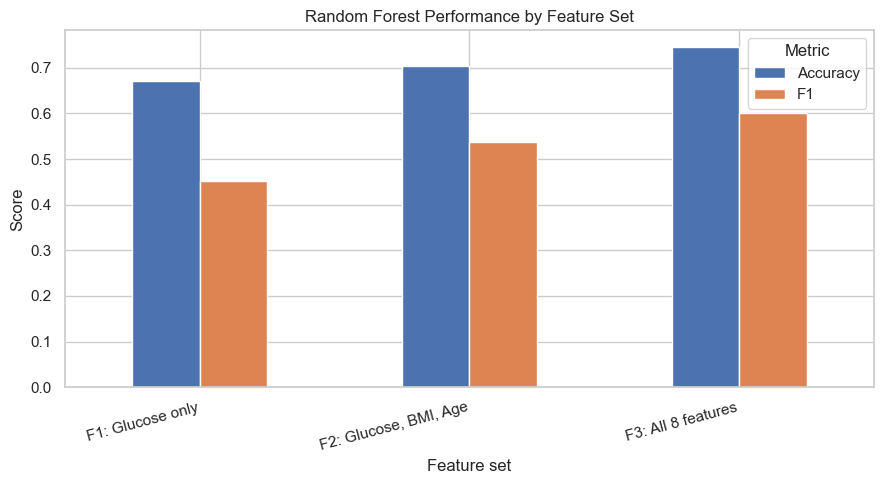

Best feature set by F1: F3: All 8 features
Interpretation: Compare the accuracy and F1 scores across the three feature sets. The difference between F1 and F3 indicates whether adding the remaining measurements helps on this particular test split.


In [15]:
feature_sets = {
    "F1: Glucose only": ["Glucose"],
    "F2: Glucose, BMI, Age": ["Glucose", "BMI", "Age"],
    "F3: All 8 features": list(X.columns)
}
feature_results = {}
for name, feats in feature_sets.items():
    rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
    rf.fit(X_train[feats], y_train)
    feature_results[name] = scores(y_test, rf.predict(X_test[feats]))

feature_results_df = pd.DataFrame(feature_results).T[["Accuracy", "Precision", "Recall", "F1"]]
display(feature_results_df.round(3))

ax = feature_results_df[["Accuracy", "F1"]].plot(kind="bar", figsize=(9, 5))
ax.set_title("Random Forest Performance by Feature Set")
ax.set_xlabel("Feature set")
ax.set_ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

best_feature_set = feature_results_df["F1"].idxmax()
print("Best feature set by F1:", best_feature_set)
print("Interpretation: Compare the accuracy and F1 scores across the three feature sets. "
      "The difference between F1 and F3 indicates whether adding the remaining measurements helps on this particular test split.")

### Q15. Conclusion and why accuracy is not enough

In [16]:
best_f1_name = results["F1"].idxmax()
best_f1 = results.loc[best_f1_name, "F1"]
baseline_f1 = results.loc["Baseline", "F1"]
best_accuracy = results.loc[best_f1_name, "Accuracy"]
best_precision = results.loc[best_f1_name, "Precision"]
best_recall = results.loc[best_f1_name, "Recall"]
top_features = importances.head(3).index.tolist()

print("Conclusion (up to 5 lines):")
print(f"1. By test F1, the recommended model among the required comparison models is {best_f1_name}.")
print(f"2. Its test accuracy is {best_accuracy:.3f}, precision is {best_precision:.3f}, recall is {best_recall:.3f}, and F1 is {best_f1:.3f}.")
print(f"3. The baseline F1 is {baseline_f1:.3f}; the selected model improves F1 by {best_f1-baseline_f1:.3f} points.")
print(f"4. Random Forest's leading importance features are {', '.join(top_features)}.")
print("5. This recommendation is based on one reproducible split and is for coursework, not clinical use.")

print("\nWhy accuracy alone is not enough:")
print("When one class is larger, a model can achieve high accuracy by mostly predicting the majority class.")
print("Precision, recall and F1 reveal whether it detects the minority class and how many false alarms or missed cases it produces.")

Conclusion (up to 5 lines):
1. By test F1, the recommended model among the required comparison models is Random Forest.
2. Its test accuracy is 0.745, precision is 0.661, recall is 0.552, and F1 is 0.602.
3. The baseline F1 is 0.000; the selected model improves F1 by 0.602 points.
4. Random Forest's leading importance features are Glucose, BMI, Age.
5. This recommendation is based on one reproducible split and is for coursework, not clinical use.

Why accuracy alone is not enough:
When one class is larger, a model can achieve high accuracy by mostly predicting the majority class.
Precision, recall and F1 reveal whether it detects the minority class and how many false alarms or missed cases it produces.


## Optional: Lower probability threshold
Predict diabetes when the estimated probability is at least 0.30, then compare precision and recall with the standard 0.50 threshold.

In [17]:
threshold = 0.30
prob_30 = forest.predict_proba(X_test)[:, 1]
pred_30 = (prob_30 >= threshold).astype(int)
threshold_comparison = pd.DataFrame(
    [scores(y_test, forest.predict(X_test)), scores(y_test, pred_30)],
    index=["Threshold 0.50 (default)", "Threshold 0.30"]
)[["Accuracy", "Precision", "Recall", "F1"]]
display(threshold_comparison.round(3))
print("Interpretation: Lowering the threshold usually classifies more cases as diabetes, which can increase recall while reducing precision. "
      "The displayed results show the actual trade-off for this test set.")

,Accuracy,Precision,Recall,F1
Threshold 0.50 (default),0.745,0.661,0.552,0.602
Threshold 0.30,0.724,0.574,0.806,0.671


Interpretation: Lowering the threshold usually classifies more cases as diabetes, which can increase recall while reducing precision. The displayed results show the actual trade-off for this test set.
